In [1]:
# 1

# Finance, data handling and numerical tools
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# File management and time tools
from pathlib import Path
from datetime import datetime

# Statistical models such as OLS regression
import statsmodels.api as sm

# Excel file creation and image insertion
from openpyxl import Workbook
from openpyxl.drawing.image import Image

# Excel styling tools
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows


In [2]:
# 2

# List of tickers to analyse
tickers = ['O', 'NNN', 'ADC', 'WPC', 'SPG', 'KIM']

# Mapping each ticker to its full company name
company_names = {
    'O':   "Realty Income Corp.",
    'NNN': "NNN REIT",
    'ADC': "Agree Realty",
    'WPC': "W. P. Carey",
    'SPG': "Simon Property Group",
    'KIM': "Kimco Realty"
}

In [3]:
# 3

# Downloading adjusted close prices for all selected tickers
data = yf.download(
    tickers,
    start="2000-01-01",
    end=None,
    auto_adjust=True
)['Close'].sort_index()

# Preview of the first rows of the dataset
data.head()


Ticker,ADC,KIM,NNN,O,SPG,WPC
Date,,,,,,
2000-01-03,2.696113,3.171892,1.971895,2.385290,6.346636,3.115810
2000-01-04,2.623572,3.142630,2.022782,2.356553,6.276505,3.104009
2000-01-05,2.575212,3.160187,2.111837,2.342183,6.329104,3.068600
2000-01-06,2.623572,3.253821,2.073670,2.370922,6.486890,3.068600
2000-01-07,2.647752,3.306489,2.111837,2.414029,6.767408,3.068600


In [4]:
# 4

# Calculation of the Daily returns based on the closing prices
# return = (today_price / yesterday_price) - 1

returns = data.pct_change().dropna()

# Preview of the first rows of the daily returns
returns.head()

Ticker,ADC,KIM,NNN,O,SPG,WPC
Date,,,,,,
2000-01-04,-0.026906,-0.009225,0.025806,-0.012048,-0.011050,-0.003788
2000-01-05,-0.018433,0.005586,0.044026,-0.006098,0.008380,-0.011407
2000-01-06,0.018779,0.029629,-0.018073,0.012270,0.024930,0.000000
2000-01-07,0.009217,0.016187,0.018405,0.018182,0.043244,0.000000
2000-01-10,0.004566,0.015930,0.042168,0.017857,0.010363,0.000000


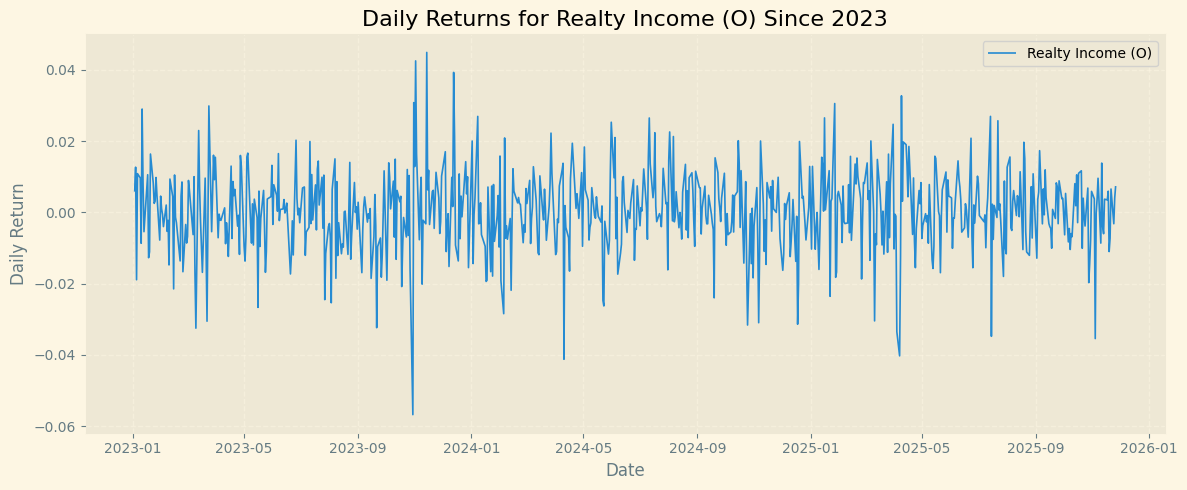

In [5]:
# 5

# Visual plot of daily returns for Realty Income starting in 2023
plt.style.use("Solarize_Light2")

# Filtering the daily returns of ticker O from 2023 onward
returns_O_2023 = returns["O"][returns.index >= "2023-01-01"]

plt.figure(figsize=(12, 5))

plt.plot(
    returns_O_2023.index,
    returns_O_2023,
    label="Realty Income (O)",
    linewidth=1.2
)


plt.title("Daily Returns for Realty Income (O) Since 2023", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Daily Return", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


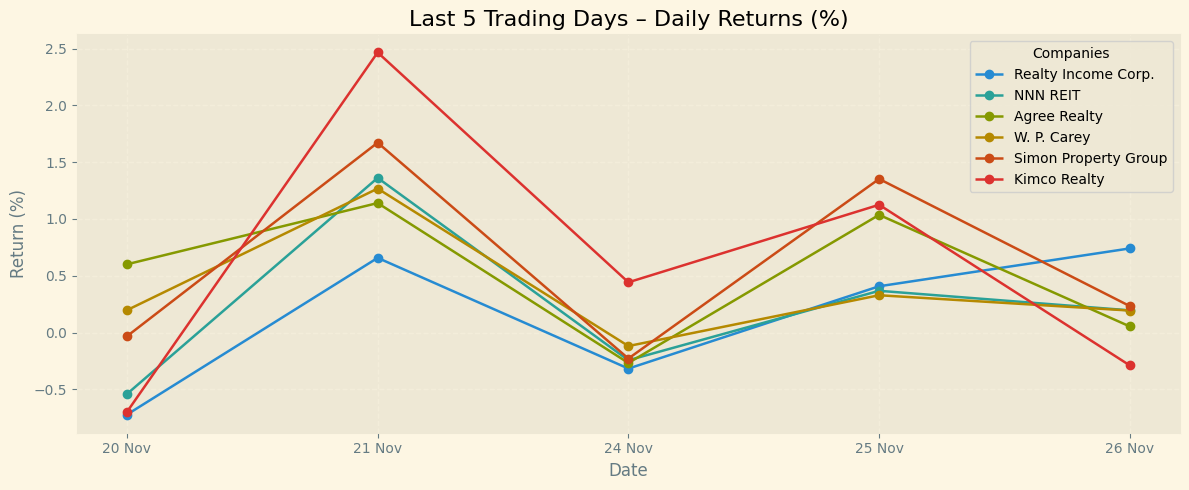

In [6]:
# 5bis

# Short-term performance: last 5 trading days (line chart)
plt.style.use("Solarize_Light2")

# 1) Select last 5 trading days
n_days = min(5, len(returns))
recent = returns.tail(n_days) * 100   # convert to %

# 2) Make dates more readable (e.g. "27 Jan")
recent.index = recent.index.strftime("%d %b")

# 3) Create figure
plt.figure(figsize=(12, 5))

# 4) Plot one line per ticker
for t in tickers:
    plt.plot(
        recent.index,
        recent[t],
        marker="o",
        linewidth=1.8,
        label=company_names[t]
    )

# 5) Cosmetics
plt.title("Last 5 Trading Days – Daily Returns (%)", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Return (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Companies", fontsize=10)
plt.tight_layout()
plt.show()


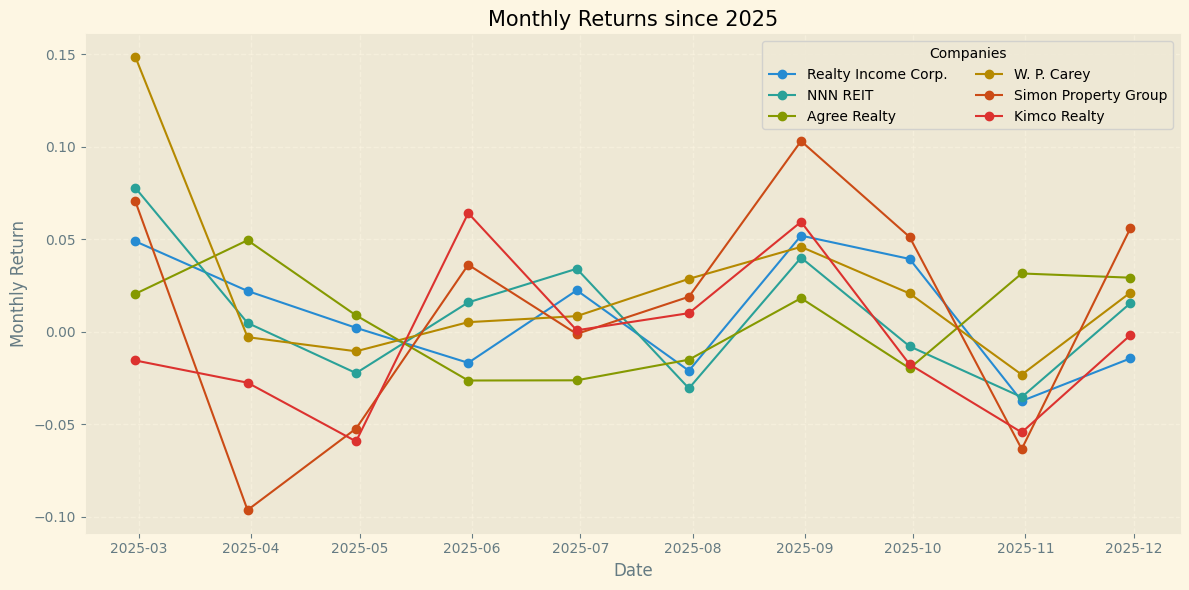

In [7]:
# 6

# Monthly returns for selected REITs (robust and simple)

plt.style.use("Solarize_Light2")

# 1) Ensure data exists (otherwise stop with a clear message)
if "data" not in globals():
    raise ValueError("Error: 'data' is not defined. Please run the earlier cell that downloads prices.")

# 2) Ensure company_names exists
if "company_names" not in globals():
    company_names = {t: t for t in tickers}

# 3) Build monthly returns (this will always work)
monthly_prices = (
    data[tickers]
    .loc["2025-01-01":]      # start date
    .resample("M")
    .last()
)

monthly_returns = monthly_prices.pct_change().dropna(how="all")

# 4) Gracefully handle empty case
if monthly_returns.empty:
    print("No monthly return data available for this period.")
else:
    # 5) Plot
    plt.figure(figsize=(12, 6))
    for col in monthly_returns.columns:
        plt.plot(
            monthly_returns.index,
            monthly_returns[col],
            label=company_names.get(col, col),
            linewidth=1.5,
            marker="o"
        )

    plt.title("Monthly Returns since 2025", fontsize=15)
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("Monthly Return", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(ncol=2, title="Companies")
    plt.tight_layout()
    plt.show()


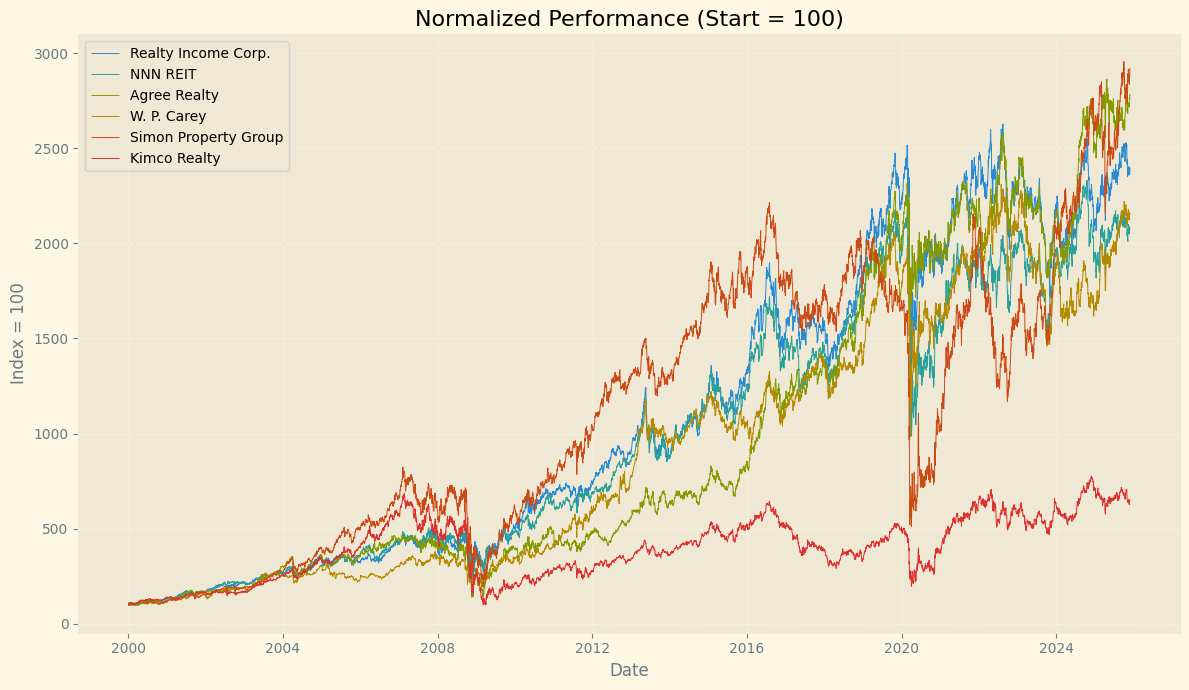

In [8]:
# 7

# Create normalized performance where each stock starts at 100
norm = data / data.iloc[0] * 100

# Long term growth of each stock with index starting at 100
plt.style.use("Solarize_Light2")
plt.figure(figsize=(12, 7))

# Plot the normalized series for every selected ticker
for t in tickers:
    plt.plot(
        norm.index,
        norm[t],
        label=company_names[t],
        linewidth=0.7
    )

plt.title("Normalized Performance (Start = 100)", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Index = 100", fontsize=12)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


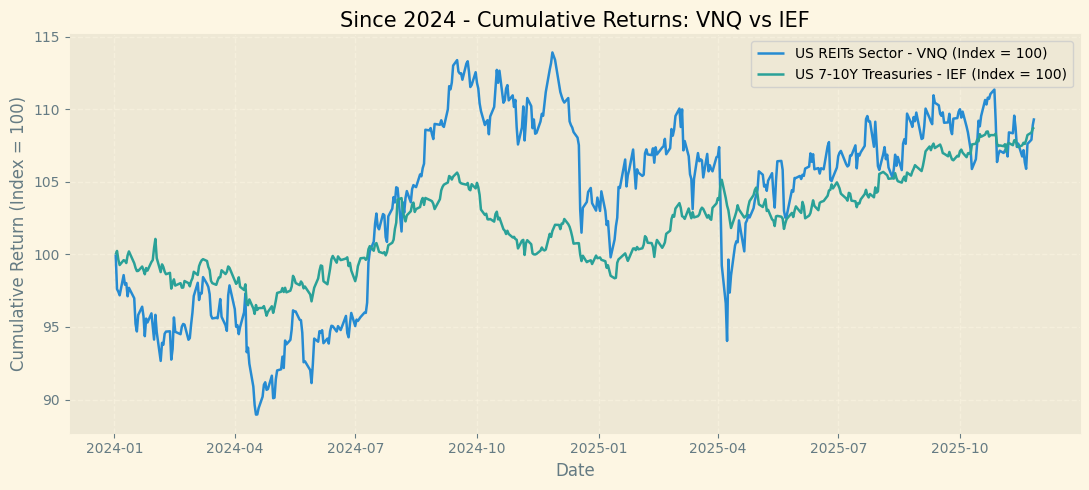

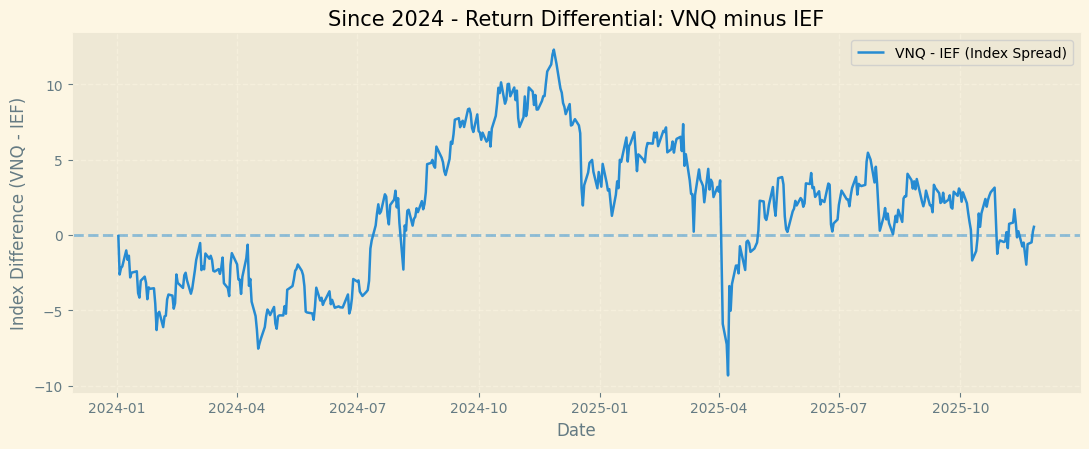

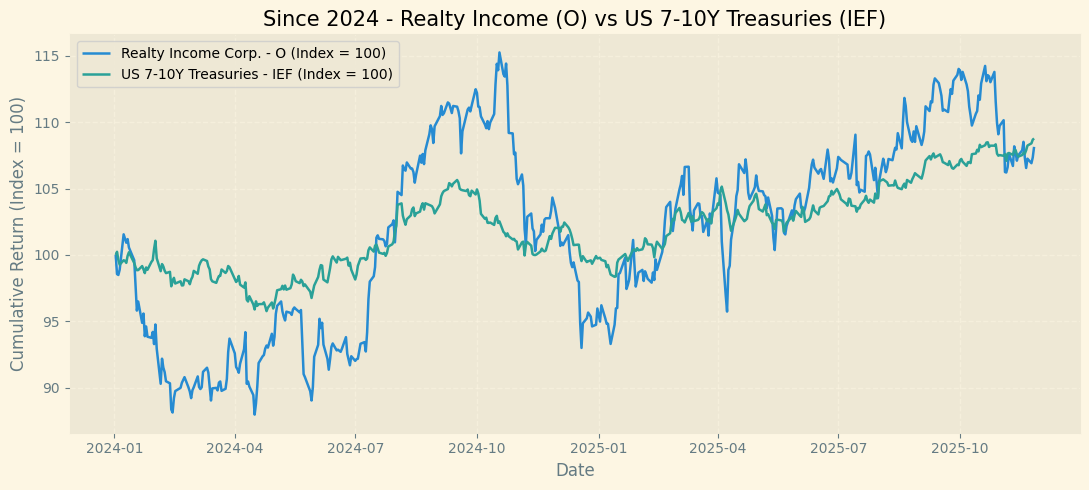

In [9]:
# 8 A

# REITs vs Treasuries since 2024 - normalized returns and differential
plt.style.use("Solarize_Light2")

bond_ticker = "IEF"    # US 7-10Y Treasuries ETF (proxy for 10Y rates)
sector_ticker = "VNQ"  # US REITs sector ETF
company_ticker = "O"   # Focus company: Realty Income Corp.

# 1) Date window: from 2024-01-01 to today
start_2024 = pd.Timestamp("2024-01-01")
end_today  = pd.Timestamp.today().normalize()

# 2) Download adjusted close prices (independent from main data)
tickers_2024 = [bond_ticker, sector_ticker, company_ticker]
px_2024 = (
    yf.download(tickers_2024, start=start_2024, end=end_today, auto_adjust=True)["Close"]
    .dropna(how="all")
)

# Safety check
if px_2024.dropna().empty or len(px_2024) < 5:
    print("Not enough data to build the 2024 REITs vs Treasuries charts.")
else:
    # 3) Normalized performance (Index = 100 on first available date)
    norm_2024 = (px_2024 / px_2024.iloc[0]) * 100

    # 4) Chart A - VNQ vs IEF
    plt.figure(figsize=(11, 5))
    plt.plot(norm_2024.index, norm_2024[sector_ticker], linewidth=1.8,
             label="US REITs Sector - VNQ (Index = 100)")
    plt.plot(norm_2024.index, norm_2024[bond_ticker], linewidth=1.8,
             label="US 7-10Y Treasuries - IEF (Index = 100)")
    plt.title("Since 2024 - Cumulative Returns: VNQ vs IEF", fontsize=15)
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("Cumulative Return (Index = 100)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 5) Chart B - VNQ minus IEF differential
    diff_vnq_ief = norm_2024[sector_ticker] - norm_2024[bond_ticker]
    plt.figure(figsize=(11, 4.6))
    plt.plot(diff_vnq_ief.index, diff_vnq_ief, linewidth=1.8, label="VNQ - IEF (Index Spread)")
    plt.axhline(0, linestyle="--", alpha=0.5)
    plt.title("Since 2024 - Return Differential: VNQ minus IEF", fontsize=15)
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("Index Difference (VNQ - IEF)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 6) Chart C - Company O vs IEF
    plt.figure(figsize=(11, 5))
    plt.plot(norm_2024.index, norm_2024[company_ticker], linewidth=1.8,
             label=f"{company_names.get(company_ticker, company_ticker)} - O (Index = 100)")
    plt.plot(norm_2024.index, norm_2024[bond_ticker], linewidth=1.8,
             label="US 7-10Y Treasuries - IEF (Index = 100)")
    plt.title("Since 2024 - Realty Income (O) vs US 7-10Y Treasuries (IEF)", fontsize=15)
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("Cumulative Return (Index = 100)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [10]:
# 8 B

# KPI calculations for performance and risk metrics

# One year total return
TR_1y = data.pct_change(252).iloc[-1]

# Annualized volatility
AnnVol = returns.std() * (252 ** 0.5)

# Maximum drawdown calculation
def max_drawdown(series):
    cum = (1 + series).cumprod()
    peak = cum.cummax()
    dd = (cum - peak) / peak
    return dd.min()

MaxDD = returns.apply(max_drawdown)

# Assemble all KPIs into one dataframe
kpi_df = pd.DataFrame({
    "TR_1y": TR_1y,
    "AnnVol": AnnVol,
    "MaxDD": MaxDD
})


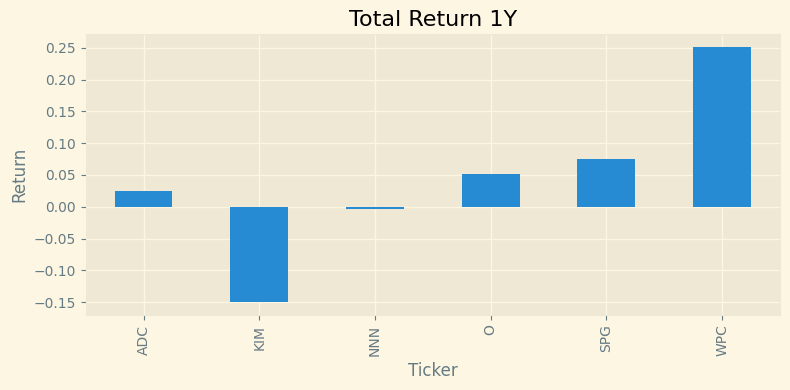

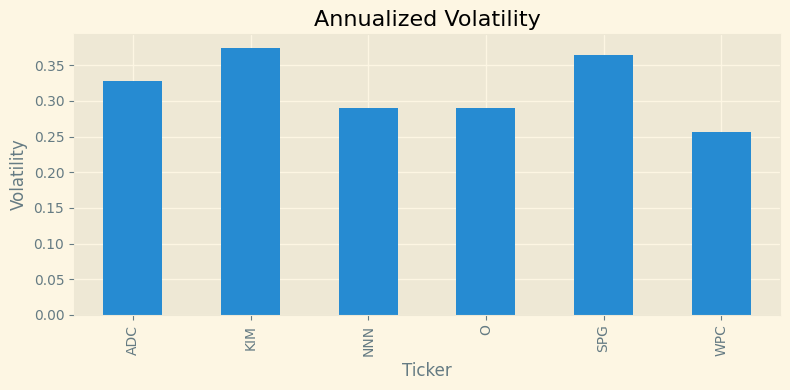

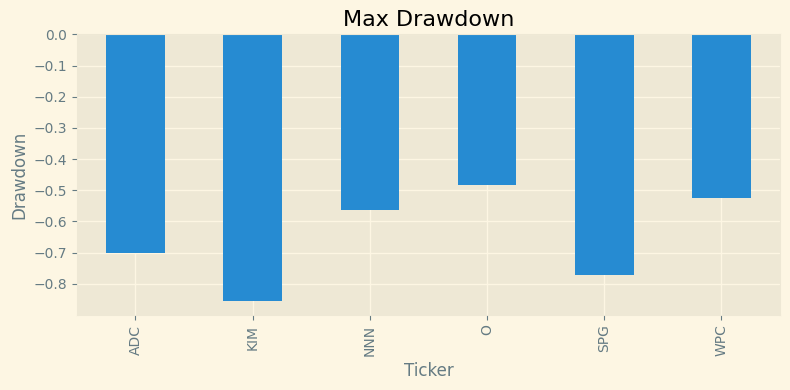

In [11]:
# 9

# KPI to plot for performance and risk metrics
plt.style.use("Solarize_Light2")

# Plot of the one year total return
kpi_df["TR_1y"].plot(kind="bar", figsize=(8, 4))
plt.title("Total Return 1Y")
plt.ylabel("Return")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# Plot of annualized volatility
kpi_df["AnnVol"].plot(kind="bar", figsize=(8, 4))
plt.title("Annualized Volatility")
plt.ylabel("Volatility")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# Plot of maximum drawdown
kpi_df["MaxDD"].plot(kind="bar", figsize=(8, 4))
plt.title("Max Drawdown")
plt.ylabel("Drawdown")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()


In [12]:
# 10

# Function that safely extracts a value from a dictionary
def _safe(d, key, default=None):
    try:
        v = d.get(key, default)
        return v if v is not None else default
    except Exception:
        return default


# Collect fundamental data for every ticker
rows = []
for t in tickers:
    tk = yf.Ticker(t)

    # Try to get the full info dictionary
    try:
        info = tk.get_info()
    except Exception:
        info = {}

    # Try to get the fast info dictionary
    try:
        f = tk.fast_info
    except Exception:
        f = {}

    # Append one row of clean data for this ticker
    rows.append({
        "Ticker": t,
        "Name": _safe(info, "longName", _safe(info, "shortName", t)),
        "Industry": _safe(info, "industry"),
        "Currency": _safe(info, "currency", _safe(f, "currency")),
        "MarketCap": _safe(info, "marketCap", _safe(f, "market_cap")),
        "Beta": _safe(info, "beta", _safe(f, "beta")),
        "PE_TTM": _safe(info, "trailingPE"),
        "PB": _safe(info, "priceToBook"),
        "52w_High": _safe(info, "fiftyTwoWeekHigh", _safe(f, "fifty_two_week_high")),
        "52w_Low": _safe(info, "fiftyTwoWeekLow", _safe(f, "fifty_two_week_low")),
        "AvgVol_3m": _safe(info, "averageVolume", _safe(f, "three_month_average_volume")),
    })

# Create the final fundamentals dataframe
fundamentals_df = pd.DataFrame(rows)
fundamentals_df


,Ticker,Name,Industry,Currency,MarketCap,Beta,PE_TTM,PB,52w_High,52w_Low,AvgVol_3m
0,O,Realty Income Corporation,REIT - Retail,USD,52563415040,0.809,53.401867,1.346022,61.09,50.71,5645080
1,NNN,"NNN REIT, Inc.",REIT - Retail,USD,7801947648,0.865,19.750002,1.764681,44.81,35.80,1282863
2,ADC,Agree Realty Corporation,REIT - Retail,USD,8662290432,0.545,43.941520,1.502530,79.65,67.58,1029290
3,WPC,W. P. Carey Inc.,REIT - Diversified,USD,14768183296,0.793,40.842426,1.810780,69.79,52.91,1179363
4,SPG,"Simon Property Group, Inc.",REIT - Retail,USD,69994528768,1.399,27.010190,26.234978,190.14,136.34,1565701
5,KIM,Kimco Realty Corporation,REIT - Retail,USD,13963764736,1.064,24.843374,1.331611,25.83,17.93,4573950


In [13]:
# 11

# Use the same plotting style
plt.style.use("ggplot")

# Copy the fundamentals dataframe and set Ticker as index
f = fundamentals_df.copy().set_index("Ticker")

# Ensure numeric columns are correctly converted to numeric type
num_cols = ["MarketCap", "Beta", "PE_TTM", "PB", "52w_High", "52w_Low", "AvgVol_3m"]
for c in num_cols:
    f[c] = pd.to_numeric(f[c], errors="coerce")

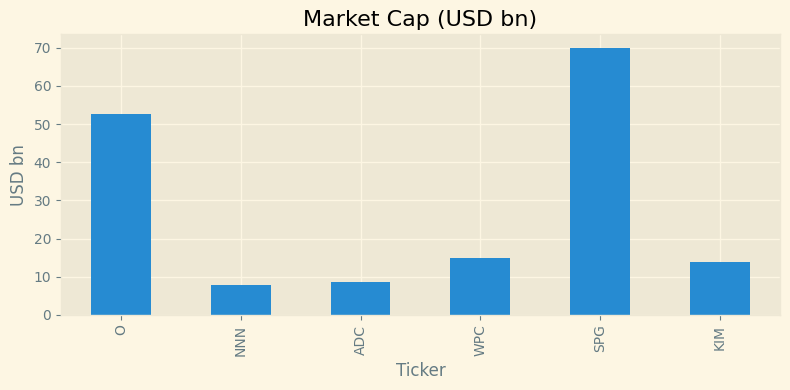

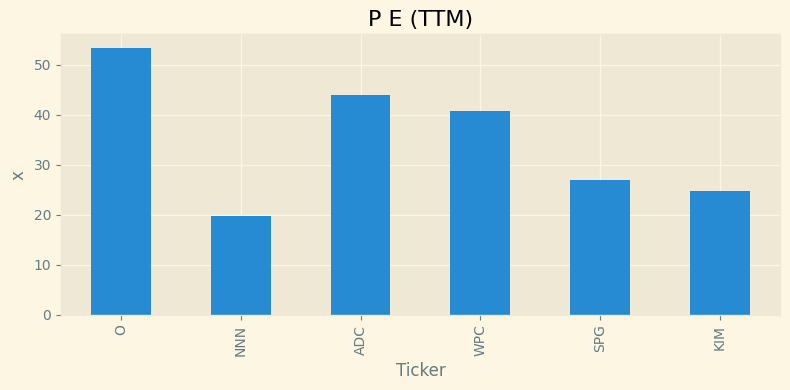

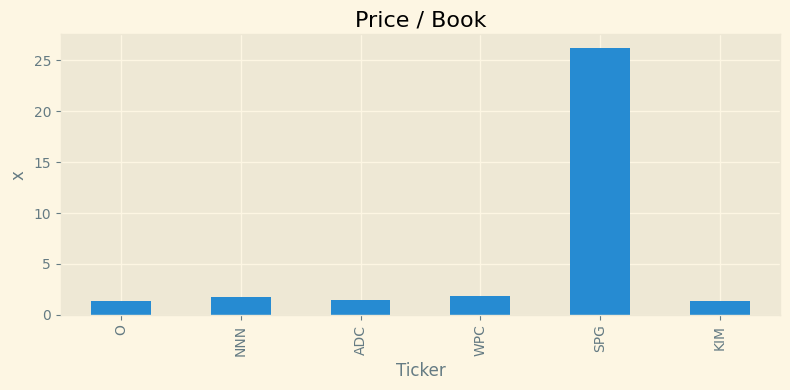

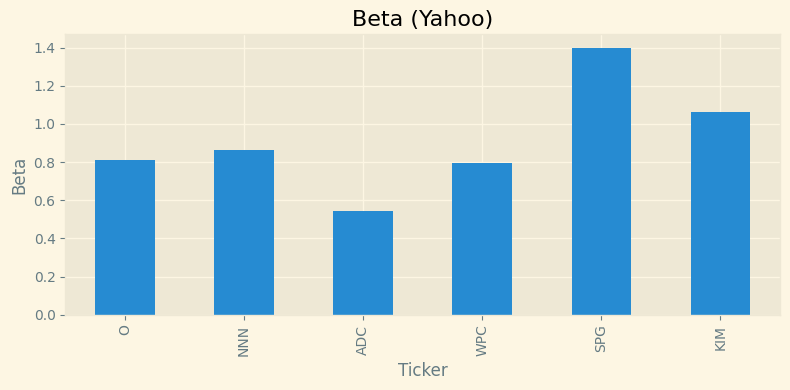

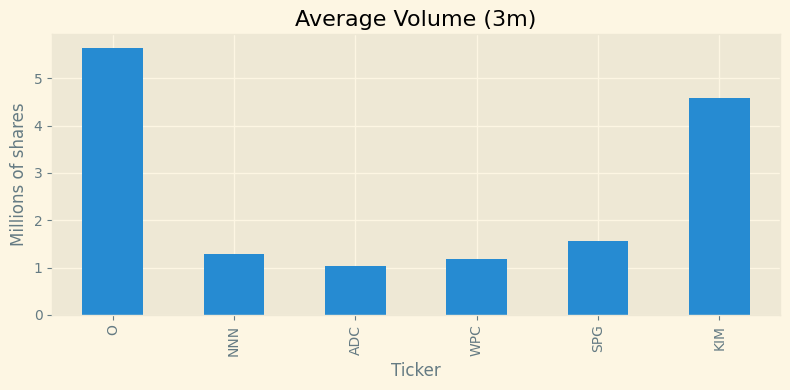

In [14]:
# 12

plt.style.use("Solarize_Light2")

# Market cap bar chart (in billions USD)
fig, ax = plt.subplots(figsize=(8, 4))
(f["MarketCap"] / 1e9).plot(kind="bar", ax=ax)
ax.set_title("Market Cap (USD bn)")
ax.set_ylabel("USD bn")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# P E TTM bar chart
if "PE_TTM" in f.columns:
    fig, ax = plt.subplots(figsize=(8, 4))
    f["PE_TTM"].plot(kind="bar", ax=ax)
    ax.set_title("P E (TTM)")
    ax.set_ylabel("x")
    ax.grid(True, axis="y")
    plt.tight_layout()
    plt.show()

# Price to Book bar chart
if "PB" in f.columns:
    fig, ax = plt.subplots(figsize=(8, 4))
    f["PB"].plot(kind="bar", ax=ax)
    ax.set_title("Price / Book")
    ax.set_ylabel("x")
    ax.grid(True, axis="y")
    plt.tight_layout()
    plt.show()

# Beta bar chart
fig, ax = plt.subplots(figsize=(8, 4))
f["Beta"].plot(kind="bar", ax=ax)
ax.set_title("Beta (Yahoo)")
ax.set_ylabel("Beta")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# Average volume 3 months bar chart (in millions)
fig, ax = plt.subplots(figsize=(8, 4))
(f["AvgVol_3m"] / 1e6).plot(kind="bar", ax=ax)
ax.set_title("Average Volume (3m)")
ax.set_ylabel("Millions of shares")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()


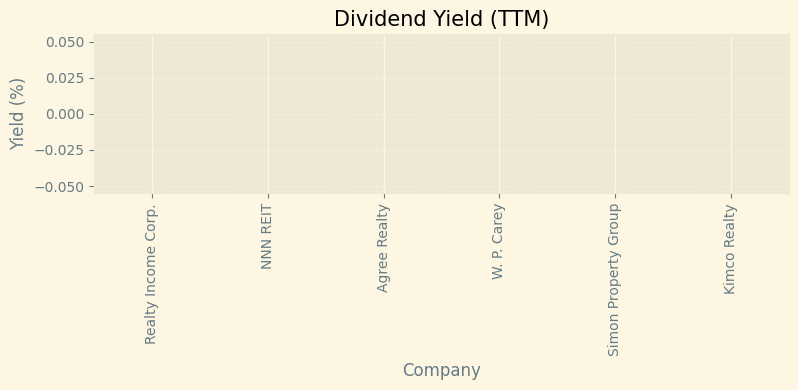

In [15]:
# 12bis

# ⚠️ NOTE ABOUT DIVIDEND DATA
# The Dividend Yield (TTM) chart is empty. This is NOT a coding error.
# Yahoo Finance often returns no dividend history for REITs in recent years,
# so yf.Ticker(t).dividends is frequently empty. As a result, the computed 12-month dividend sum is 0 → yield is 0 → bars are not visible.

# Dividend Yield (TTM) for each company — from last 12 months of dividends
plt.style.use("Solarize_Light2")

def compute_dividend_yield_ttm(tickers, price_df):
    """
    Returns a DataFrame with TTM dividend yield (%) for each ticker.
    TTM dividend = sum of dividends over the last 365 days.
    Yield = TTM dividend / last available close * 100.
    """
    results = []
    if price_df.empty:
        return pd.DataFrame(columns=["Ticker", "DividendYield_TTM_%"]).set_index("Ticker")

    end_date = price_df.index.max()
    start_date = end_date - pd.Timedelta(days=365)
    last_prices = price_df.loc[end_date, tickers]

    for t in tickers:
        try:
            div = yf.Ticker(t).dividends
            if div is None or len(div) == 0:
                ttm_div = float("nan")
            else:
                # keep only dividends in the last 12 months
                ttm_div = div.loc[div.index >= start_date].sum()
            price = last_prices.get(t, float("nan"))
            yld = (ttm_div / price) * 100 if pd.notna(ttm_div) and pd.notna(price) and price != 0 else float("nan")
        except Exception:
            yld = float("nan")

        results.append({"Ticker": t, "DividendYield_TTM_%": yld})

    return pd.DataFrame(results).set_index("Ticker")

# 1) Compute TTM dividend yields
div_yield = compute_dividend_yield_ttm(tickers, data)

# 2) Bar chart with full company names as labels
ax = (
    div_yield["DividendYield_TTM_%"]
    .rename(index=lambda t: company_names.get(t, t))
    .plot(kind="bar", figsize=(8, 4))
)

ax.set_title("Dividend Yield (TTM)", fontsize=15)
ax.set_ylabel("Yield (%)", fontsize=12)
ax.set_xlabel("Company", fontsize=12)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


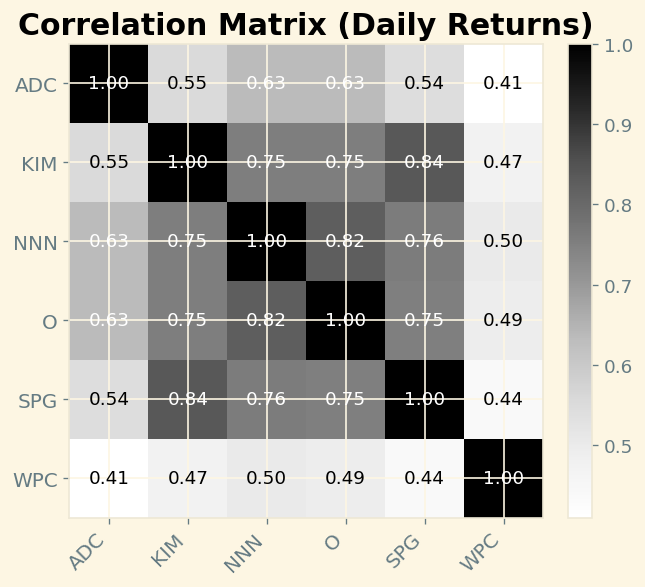

In [16]:
# 13

# Correlation matrix of daily returns (always recomputed inside this block)

# 1) Safety check
if "returns" not in globals():
    raise ValueError("Error: 'returns' is not defined. Please run the earlier block that computes daily returns.")

# 2) Compute correlation matrix locally
corr = returns.corr()

# 3) Plot
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)

im = ax.imshow(
    corr.values,
    interpolation="nearest",
    cmap="Greys"
)

# Labels
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=12)

ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index, fontsize=12)

ax.set_title("Correlation Matrix (Daily Returns)", fontsize=18, fontweight="bold")

# Annotate numbers
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        val = corr.values[i, j]
        color = "white" if val > 0.6 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=11)

# Color bar
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=11)

plt.tight_layout()
plt.show()


In [17]:
# THEN ALL THE STATISTICAL ANALYSIS AT THE BOTTOM ------->

In [18]:
# 14
 
# Shifted target: next day's price
data['O_next'] = data['O'].shift(-1)

# Feature: today's price
X = data[['O']]  
y = data['O_next']

# Remove last row with NaN target
X = X.iloc[:-1]
y = y.iloc[:-1]

X.head(), y.head()


(Ticker             O
 Date                
 2000-01-03  2.385290
 2000-01-04  2.356553
 2000-01-05  2.342183
 2000-01-06  2.370922
 2000-01-07  2.414029,
 Date
 2000-01-03    2.356553
 2000-01-04    2.342183
 2000-01-05    2.370922
 2000-01-06    2.414029
 2000-01-07    2.457137
 Name: O_next, dtype: float64)

In [19]:
# 15
 
# Add constant for intercept
X = sm.add_constant(X)
# Fit OLS regression
ols_model = sm.OLS(y, X).fit()

# Show summary
ols_model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 O_next   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 9.540e+06
Date:                Fri, 28 Nov 2025   Prob (F-statistic):               0.00
Time:                        11:52:55   Log-Likelihood:                -4649.6
No. Observations:                6515   AIC:                             9303.
Df Residuals:                    6513   BIC:                             9317.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0150      0.010      1.440      0.150      -0.005       0.035
O              0.9997      0.000   3088.678      0.000       0.999       1.000
==============================================================================
Omnibus:                     6372.593   Durbin-Watson:                   2.108
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          2935662.674
Skew:                          -3.961   Prob(JB):                         0.00
Kurtosis:                     106.690   Cond. No.                         54.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [20]:
# 16

# Predict next-day prices
y_pred = ols_model.predict(X)

# Compare first 100 actual vs predicted
comparison = pd.DataFrame({'Actual': y, 'Predicted': y_pred})
comparison.head(100)


,Actual,Predicted
Date,,
2000-01-03,2.356553,2.399670
2000-01-04,2.342183,2.370941
2000-01-05,2.370922,2.356574
2000-01-06,2.414029,2.385306
2000-01-07,2.457137,2.428402
...,...,...
2000-05-18,2.676142,2.697884
2000-05-19,2.720748,2.690449
2000-05-22,2.720748,2.735043


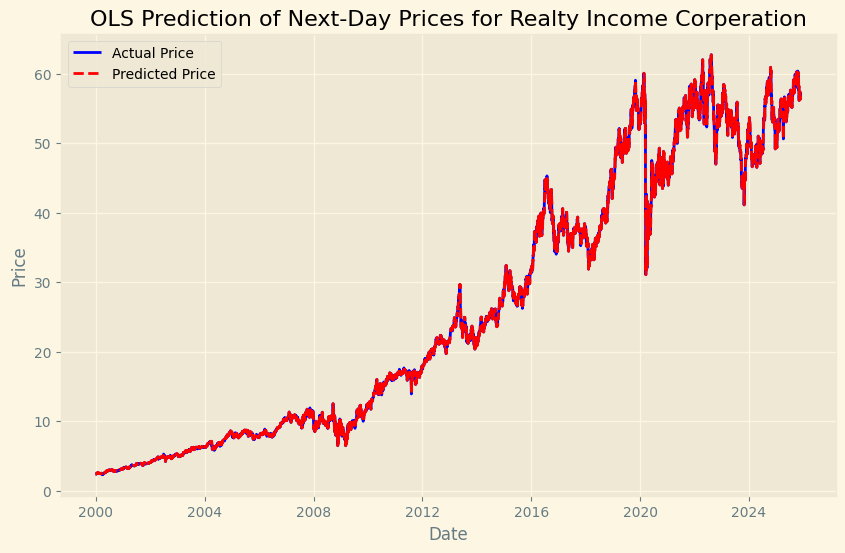

In [21]:
# 17

plt.figure(figsize=(10, 6))
plt.plot(y.index, y, label='Actual Price', color='blue')
plt.plot(y.index, y_pred, label='Predicted Price', color='red', linestyle='--')
plt.title('OLS Prediction of Next-Day Prices for Realty Income Corperation')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

In [22]:
# 18

# Target and features for 10-day forward return prediction (ticker O)
plt.style.use("Solarize_Light2")

# Target: 10-day forward return = P(t+10)/P(t) - 1
target_10d = data["O"].shift(-10) / data["O"] - 1

# Basic price-based features
feat = pd.DataFrame(index=data.index)
feat["ret_1d"]   = returns["O"]                         # daily return
feat["ret_5d"]   = data["O"].pct_change(5)             # 5-day return
feat["ma10_ma20"]= data["O"].rolling(10).mean() / data["O"].rolling(20).mean() - 1  # short vs mid
feat["vol_10d"]  = returns["O"].rolling(10).std()      # 10-day realized vol

# Macro style features: REIT sector and 7-10Y treasuries daily returns (aligned)
try:
    helper_px = yf.download(["VNQ", "IEF"], start=data.index.min(), end=None, auto_adjust=True)["Close"]
    helper_ret = helper_px.pct_change()
    feat["ret_vnq"] = helper_ret["VNQ"]
    feat["ret_ief"] = helper_ret["IEF"]
except Exception:
    # If download fails, keep NaNs so rows will be dropped cleanly
    feat["ret_vnq"] = pd.NA
    feat["ret_ief"] = pd.NA

# Assemble modeling table and drop rows with NaNs or unavailable target
df_model = pd.concat([feat, target_10d.rename("y_10d")], axis=1).dropna()
df_model.head()


,ret_1d,ret_5d,ma10_ma20,vol_10d,ret_vnq,ret_ief,y_10d
Date,,,,,,,
2004-09-30,0.002895,0.021429,0.004061,0.006052,0.008025,-0.001046,0.037087
2004-10-01,0.024872,0.043302,0.005875,0.009261,0.018507,-0.004006,0.019719
2004-10-04,-0.001301,0.044059,0.008130,0.008980,0.004299,0.000351,0.030592
2004-10-05,-0.000867,0.028774,0.010246,0.009122,-0.000194,0.000000,0.025624
2004-10-06,0.009771,0.035634,0.013431,0.008466,0.004670,-0.003282,0.013763


In [23]:
# 19

# Time-based train test split (no leakage)
split_idx = int(len(df_model) * 0.8)
train = df_model.iloc[:split_idx].copy()
test  = df_model.iloc[split_idx:].copy()

X_train = sm.add_constant(train.drop(columns=["y_10d"]))
y_train = train["y_10d"]
X_test  = sm.add_constant(test.drop(columns=["y_10d"]))
y_test  = test["y_10d"]

# Fit simple and interpretable OLS
ols_10d = sm.OLS(y_train, X_train).fit()

# Quick text summary line for the notebook
print("Train R2:", round(ols_10d.rsquared, 3))


Train R2: 0.021


In [24]:
# 20

# Evaluate on the test set
y_pred_test = ols_10d.predict(X_test)

# Metrics
r2_test  = 1 - ((y_test - y_pred_test)**2).sum() / ((y_test - y_test.mean())**2).sum()
mae_test = (y_test - y_pred_test).abs().mean()
print("Test R2:", round(float(r2_test), 3))
print("Test MAE:", round(float(mae_test), 6))

# Coefficients table (sorted by absolute value, excluding constant)
coef = ols_10d.params.drop("const").sort_values(key=lambda s: s.abs(), ascending=False)
coef


Test R2: -0.041
Test MAE: 0.031405


ret_ief      0.767464
ma10_ma20   -0.148802
ret_vnq     -0.103922
ret_5d      -0.079682
ret_1d      -0.047196
vol_10d     -0.042631
dtype: float64

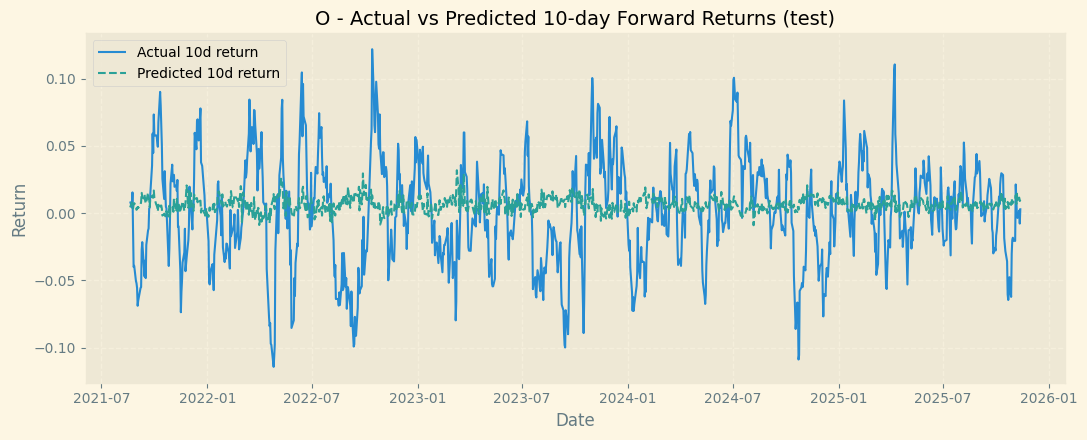

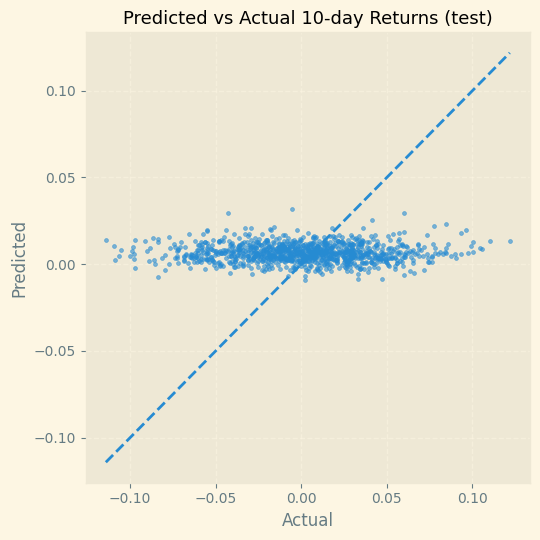

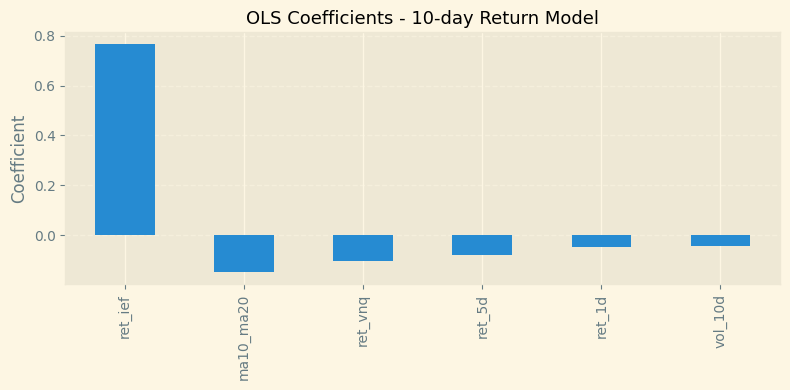

In [25]:
# 21 

# Graphics for the 10-day return model

# A) Actual vs predicted 10-day returns over time (test period)
plt.figure(figsize=(11, 4.5))
plt.plot(y_test.index, y_test, label="Actual 10d return", linewidth=1.5)
plt.plot(y_test.index, y_pred_test, label="Predicted 10d return", linewidth=1.5, linestyle="--")
plt.title("O - Actual vs Predicted 10-day Forward Returns (test)", fontsize=14)
plt.xlabel("Date"); plt.ylabel("Return")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend()
plt.tight_layout(); plt.show()

# B) Scatter plot with y = x reference
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, y_pred_test, s=8, alpha=0.6)
minv = float(min(y_test.min(), y_pred_test.min()))
maxv = float(max(y_test.max(), y_pred_test.max()))
plt.plot([minv, maxv], [minv, maxv], linestyle="--")
plt.title("Predicted vs Actual 10-day Returns (test)", fontsize=13)
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

# C) Feature importance by OLS coefficient magnitude
plt.figure(figsize=(8, 4))
coef.plot(kind="bar")
plt.title("OLS Coefficients - 10-day Return Model", fontsize=13)
plt.ylabel("Coefficient")
plt.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()


In [26]:


# ---------- helpers ----------
def _ensure_returns(prices: pd.DataFrame) -> pd.DataFrame:
    r = prices.pct_change().dropna(how="all")
    return r

def _max_dd(series: pd.Series) -> float:
    cum = (1 + series).cumprod()
    peak = cum.cummax()
    dd = (cum - peak) / peak
    return float(dd.min())

def _save_fig(fig, out_dir: Path, name: str, dpi=120) -> Path:
    out_dir.mkdir(parents=True, exist_ok=True)
    p = out_dir / f"{name}.png"
    fig.savefig(p, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    return p

def _anchor_image(ws, img_path: Path, cell="B6", max_width=720, max_height=360):
    img = XLImage(str(img_path))
    # scale to fit
    scale_w = max_width / img.width
    scale_h = max_height / img.height
    scale = min(scale_w, scale_h, 1.0)
    img.width = int(img.width * scale)
    img.height = int(img.height * scale)
    ws.add_image(img, cell)

def _add_title(ws, text, row=1, col=2):
    c = ws.cell(row=row, column=col, value=text)
    c.font = Font(b=True, size=14)
    ws.merge_cells(start_row=row, start_column=col, end_row=row, end_column=12)
    ws.row_dimensions[row].height = 24

def _add_subtitle(ws, text, row=2, col=2):
    c = ws.cell(row=row, column=col, value=text)
    c.font = Font(italic=True, size=11, color="666666")
    ws.merge_cells(start_row=row, start_column=col, end_row=row, end_column=12)
    ws.row_dimensions[row].height = 18

def _standard_sheet(ws):
    ws.sheet_view.showGridLines = False
    # comfortable column widths
    for col in range(2, 15):
        ws.column_dimensions[chr(64+col if col <= 26 else 64)].width = 14

thin = Side(style="thin", color="DDDDDD")
thin_border = Border(left=thin, right=thin, top=thin, bottom=thin)

# ---------- recompute minimal inputs safely ----------
# prices
if 'data' not in globals():
    raise RuntimeError("Price dataframe 'data' is missing. Run the earlier download cell first.")

# friendly names
if 'company_names' not in globals():
    company_names = {t: t for t in data.columns}

# daily returns
returns = _ensure_returns(data)

# monthly returns since 2025
monthly_prices = (
    data[tickers]
    .loc["2025-01-01":]
    .resample("ME").last()
)
monthly_returns = monthly_prices.pct_change().dropna(how="all")

# KPIs
TR_1y = data.pct_change(252).iloc[-1]
AnnVol = returns.std() * np.sqrt(252)
MaxDD = returns.apply(_max_dd)

kpi_df = pd.DataFrame({"TR_1y": TR_1y, "AnnVol": AnnVol, "MaxDD": MaxDD})

# fundamentals_df (if not present, create a placeholder so export still works)
if 'fundamentals_df' not in globals():
    fundamentals_df = pd.DataFrame(
        index=tickers,
        data={'Name':[company_names.get(t,t) for t in tickers]}
    ).reset_index().rename(columns={"index":"Ticker"})

# correlation
corr = returns.corr()

# ---------- create figures (compact size; no show) ----------

def _anchor_image(ws, img_path: Path, cell="B6", max_width=720, max_height=360):
    from openpyxl.drawing.image import Image  # local import avoids scope issues
    img = Image(str(img_path))
    # scale to fit
    scale_w = max_width / img.width
    scale_h = max_height / img.height
    scale = min(scale_w, scale_h, 1.0)
    img.width = int(img.width * scale)
    img.height = int(img.height * scale)
    ws.add_image(img, cell)


_tmp = Path.cwd() / "_export_png"
fig_w = 8.5   # inches
fig_h = 4.2

# 1) Daily returns O since 2023
if 'O' in data.columns:
    ret_O_2023 = returns['O'][returns.index >= "2023-01-01"]
    fig = plt.figure(figsize=(fig_w, fig_h))
    plt.plot(ret_O_2023.index, ret_O_2023, linewidth=1.2, label="Realty Income (O)")
    plt.title("Daily Returns for Realty Income (O) Since 2023")
    plt.xlabel("Date"); plt.ylabel("Daily Return"); plt.grid(True, linestyle="--", alpha=0.4); plt.legend()
    p_daily_O = _save_fig(fig, _tmp, "1_daily_O")

# 2) Last 5 trading days — multi-line
n_days = min(5, len(returns))
recent = returns.tail(n_days) * 100
fig = plt.figure(figsize=(fig_w, fig_h))
for t in tickers:
    plt.plot(recent.index.strftime("%d %b"), recent[t], marker="o", linewidth=1.6, label=company_names.get(t,t))
plt.title("Last 5 Trading Days — Daily Returns (%)"); plt.xlabel("Date"); plt.ylabel("Return (%)")
plt.grid(True, linestyle="--", alpha=0.4); plt.legend(ncol=2, fontsize=9)
p_last5 = _save_fig(fig, _tmp, "2_last5")

# 3) Monthly returns since 2025
fig = plt.figure(figsize=(fig_w, fig_h))
for t in monthly_returns.columns:
    plt.plot(monthly_returns.index, monthly_returns[t], marker="o", linewidth=1.4, label=company_names.get(t,t))
plt.title("Monthly Returns since 2025"); plt.xlabel("Date"); plt.ylabel("Monthly Return")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend(ncol=2, fontsize=9)
p_monthly = _save_fig(fig, _tmp, "3_monthly")

# 4) Normalized performance (Index 100)
norm = data / data.iloc[0] * 100
fig = plt.figure(figsize=(fig_w, fig_h))
for t in tickers:
    plt.plot(norm.index, norm[t], linewidth=1.0, label=company_names.get(t,t))
plt.title("Normalized Performance (Start = 100)"); plt.xlabel("Date"); plt.ylabel("Index = 100")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend(ncol=2, fontsize=9)
p_norm = _save_fig(fig, _tmp, "4_normalized")

# 5) VNQ vs IEF since 2024 + differential + O vs IEF
# (downloaded earlier in your notebook; here we rebuild from 'data' if present, else skip gracefully)
try:
    import yfinance as yf
    start_2024 = pd.Timestamp("2024-01-01")
    px_2024 = yf.download(["IEF","VNQ","O"], start=start_2024, auto_adjust=True)['Close'].dropna(how="all")
    norm_2024 = (px_2024 / px_2024.iloc[0]) * 100

    # A) VNQ vs IEF
    fig = plt.figure(figsize=(fig_w, fig_h))
    plt.plot(norm_2024.index, norm_2024["VNQ"], linewidth=1.6, label="US REITS Sector – VNQ (Index = 100)")
    plt.plot(norm_2024.index, norm_2024["IEF"], linewidth=1.6, label="US 7–10Y Treasuries – IEF (Index = 100)")
    plt.title("Since 2024 – Cumulative Returns: VNQ vs IEF"); plt.xlabel("Date"); plt.ylabel("Cumulative Return (Index = 100)")
    plt.grid(True, linestyle="--", alpha=0.5); plt.legend(fontsize=9)
    p_vnq_ief = _save_fig(fig, _tmp, "5a_vnq_ief")

    # B) Differential
    diff = norm_2024["VNQ"] - norm_2024["IEF"]
    fig = plt.figure(figsize=(fig_w, fig_h))
    plt.plot(diff.index, diff, linewidth=1.6, label="VNQ - IEF (Index Spread)")
    plt.axhline(0, linestyle="--", alpha=0.5)
    plt.title("Since 2024 – Return Differential: VNQ minus IEF")
    plt.xlabel("Date"); plt.ylabel("Index Difference (VNQ - IEF)")
    plt.grid(True, linestyle="--", alpha=0.5); plt.legend(fontsize=9)
    p_diff = _save_fig(fig, _tmp, "5b_diff")

    # C) O vs IEF
    if "O" in norm_2024:
        fig = plt.figure(figsize=(fig_w, fig_h))
        plt.plot(norm_2024.index, norm_2024["O"], linewidth=1.6, label="Realty Income Corp. – O (Index = 100)")
        plt.plot(norm_2024.index, norm_2024["IEF"], linewidth=1.6, label="US 7–10Y Treasuries – IEF (Index = 100)")
        plt.title("Since 2024 – Realty Income (O) vs US 7–10Y Treasuries (IEF)")
        plt.xlabel("Date"); plt.ylabel("Cumulative Return (Index = 100)")
        plt.grid(True, linestyle="--", alpha=0.5); plt.legend(fontsize=9)
        p_O_ief = _save_fig(fig, _tmp, "5c_O_ief")
    else:
        p_O_ief = None
except Exception:
    p_vnq_ief = p_diff = p_O_ief = None

# 6) KPI bar charts (TR_1y, AnnVol, MaxDD)
def _bar(fig_title, s, ylabel):
    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = s.reindex(tickers).plot(kind="bar")
    plt.title(fig_title); plt.xlabel("Ticker"); plt.ylabel(ylabel); plt.grid(True, axis="y")
    return fig

p_TR   = _save_fig(_bar("Total Return 1Y", kpi_df["TR_1y"], "Return"), _tmp, "6a_TR1y")
p_vol  = _save_fig(_bar("Annualized Volatility", kpi_df["AnnVol"], "Volatility"), _tmp, "6b_AnnVol")
p_dd   = _save_fig(_bar("Max Drawdown", kpi_df["MaxDD"], "Drawdown"), _tmp, "6c_MaxDD")

# 7) Fundamentals bar charts (if numeric columns exist)
num_df = fundamentals_df.copy()
if "Ticker" in num_df.columns:
    num_df = num_df.set_index("Ticker")
# attempt coercion
for col in ["MarketCap","Beta","PE_TTM","PB","AvgVol_3m"]:
    if col in num_df.columns:
        num_df[col] = pd.to_numeric(num_df[col], errors="coerce")

def _bar_fund(title, series, ylabel):
    fig = plt.figure(figsize=(fig_w, fig_h))
    series.reindex(tickers).plot(kind="bar")
    plt.title(title); plt.xlabel("Ticker"); plt.ylabel(ylabel); plt.grid(True, axis="y")
    return fig

p_mcap = _save_fig(_bar_fund("Market Cap (USD bn)", (num_df.get("MarketCap", pd.Series(index=tickers)) / 1e9), "USD bn"), _tmp, "7a_mcap")
p_pe   = _save_fig(_bar_fund("P E (TTM)", num_df.get("PE_TTM", pd.Series(index=tickers)), "x"), _tmp, "7b_pe")
p_pb   = _save_fig(_bar_fund("Price / Book", num_df.get("PB", pd.Series(index=tickers)), "x"), _tmp, "7c_pb")
p_beta = _save_fig(_bar_fund("Beta (Yahoo)", num_df.get("Beta", pd.Series(index=tickers)), "Beta"), _tmp, "7d_beta")
p_vol3 = _save_fig(_bar_fund("Average Volume (3m)", (num_df.get("AvgVol_3m", pd.Series(index=tickers)) / 1e6), "Millions of shares"), _tmp, "7e_vol3")

# 8) Correlation heatmap (black = high corr, white = low)
fig = plt.figure(figsize=(6.2, 4.8), dpi=120)
ax = plt.gca()
im = ax.imshow(corr.values, interpolation="nearest", cmap="Greys")
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(corr.index)));   ax.set_yticklabels(corr.index, fontsize=9)
plt.title("Correlation Matrix (Daily Returns)")
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        val = corr.values[i, j]
        color = "white" if val > 0.6 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=8)
plt.tight_layout()
p_corr = _save_fig(fig, _tmp, "8_corr")

# ---------- create workbook ----------
wb = Workbook()
# remove default
wb.remove(wb.active)

# file path
downloads = Path.home() / "Downloads"
ts = datetime.now().strftime("%Y%m%d_%H%M")
outfile = downloads / f"REIT_IB_Analysis_FULL_{ts}.xlsx"

# ----- Tab 0: Summary -----
ws = wb.create_sheet("0_Summary")
_standard_sheet(ws)

# Decorative header
ws.merge_cells("B2:L3")
h = ws["B2"]
h.value = "Real Estate – Python Analyst Pack"
h.font = Font(size=16, bold=True, color="FFFFFF")
h.alignment = Alignment(horizontal="center", vertical="center")
h.fill = PatternFill("solid", fgColor="4472C4")

# Subtitle bar
ws.merge_cells("B4:L4")
sub = ws["B4"]
sub.value = "Automated export • compact charts • aligned layout • gridlines hidden"
sub.font = Font(italic=True, color="FFFFFF")
sub.alignment = Alignment(horizontal="center", vertical="center")
sub.fill = PatternFill("solid", fgColor="70AD47")
ws.row_dimensions[2].height = 30
ws.row_dimensions[4].height = 20

# Table of contents
toc = [
    ("1", "Returns Views"),
    ("2", "Normalized Performance (Index 100)"),
    ("3", "REITs vs Treasuries (since 2024)"),
    ("4", "KPIs: Total Return 1Y, Volatility, MaxDD"),
    ("5", "Fundamentals — Table"),
    ("6", "Fundamentals — Bar Charts"),
    ("7", "Correlation Matrix (Daily Returns)"),
    ("8", "Adjusted Close Prices — Table")
]
_start = 7
ws.cell(row=_start-1, column=2, value="Table of Contents").font = Font(b=True, size=12)
for i, (num, title) in enumerate(toc, start=_start):
    ws.cell(row=i, column=2, value=int(num)).font = Font(b=True)
    ws.cell(row=i, column=3, value=title)
    # light borders
    for c in (2,3):
        ws.cell(row=i, column=c).border = thin_border
ws.column_dimensions["B"].width = 10
ws.column_dimensions["C"].width = 70

# ----- Tab 1: Returns -----
ws = wb.create_sheet("1_Returns")
_standard_sheet(ws)
_add_title(ws, "Short- and Medium-term Returns")
_add_subtitle(ws, "Daily (O) since 2023 • Last 5 trading days • Monthly since 2025")

_anchor_image(ws, p_daily_O, cell="B6",  max_width=720, max_height=300)
_anchor_image(ws, p_last5,   cell="B22", max_width=720, max_height=300)
_anchor_image(ws, p_monthly, cell="B38", max_width=720, max_height=300)

# ----- Tab 2: Normalized -----
ws = wb.create_sheet("2_Normalized")
_standard_sheet(ws)
_add_title(ws, "Normalized Performance (Start = 100)")
_add_subtitle(ws, "Long-run indexed trajectories for all companies")
_anchor_image(ws, p_norm, cell="B6", max_width=720, max_height=420)

# ----- Tab 3: REITs vs Treasuries -----
ws = wb.create_sheet("3_Rel_vs_Treasuries")
_standard_sheet(ws)
_add_title(ws, "REITs vs US 7–10Y Treasuries (since 2024)")
_add_subtitle(ws, "VNQ vs IEF • Differential • O vs IEF (index = 100)")

if p_vnq_ief: _anchor_image(ws, p_vnq_ief, cell="B6",  max_width=720, max_height=300)
if p_diff:    _anchor_image(ws, p_diff,    cell="B22", max_width=720, max_height=300)
if p_O_ief:   _anchor_image(ws, p_O_ief,   cell="B38", max_width=720, max_height=300)

# ----- Tab 4: KPIs -----
ws = wb.create_sheet("4_KPIs")
_standard_sheet(ws)
_add_title(ws, "Key Risk & Performance Metrics")
_add_subtitle(ws, "Total Return 1Y • Annualized Volatility • Maximum Drawdown")
_anchor_image(ws, p_TR,  cell="B6",  max_width=720, max_height=300)
_anchor_image(ws, p_vol, cell="B22", max_width=720, max_height=300)
_anchor_image(ws, p_dd,  cell="B38", max_width=720, max_height=300)

# ----- Tab 5: Fundamentals table -----
ws = wb.create_sheet("5_Fundamentals_Table")
_standard_sheet(ws)
_add_title(ws, "Company Fundamentals — Table")
_add_subtitle(ws, "Directly pulled; numbers are indicative (Yahoo Finance fast/info)")

tbl = fundamentals_df.copy()
# nice column order if present
preferred_cols = ["Ticker","Name","Industry","Currency","MarketCap","Beta","PE_TTM","PB","52w_High","52w_Low","AvgVol_3m"]
cols = [c for c in preferred_cols if c in tbl.columns] + [c for c in tbl.columns if c not in preferred_cols]
tbl = tbl[cols]

start_row = 6
start_col = 2
# header
for j, col in enumerate(tbl.columns, start=start_col):
    cell = ws.cell(row=start_row, column=j, value=col)
    cell.font = Font(b=True)
    cell.fill = PatternFill("solid", fgColor="F2F2F2")
    cell.border = thin_border
# rows
for i, row in enumerate(tbl.itertuples(index=False), start=start_row+1):
    for j, val in enumerate(row, start=start_col):
        cell = ws.cell(row=i, column=j, value=val)
        cell.border = thin_border
# widths
for j in range(start_col, start_col+len(tbl.columns)):
    ws.column_dimensions[chr(64+j)].width = 16

# ----- Tab 6: Fundamentals charts -----
ws = wb.create_sheet("6_Fundamentals_Charts")
_standard_sheet(ws)
_add_title(ws, "Fundamentals — Bar Charts")
_add_subtitle(ws, "Market Cap • PE • Price/Book • Beta • 3m Avg Volume")
_anchor_image(ws, p_mcap, cell="B6",  max_width=720, max_height=260)
_anchor_image(ws, p_pe,   cell="B22", max_width=720, max_height=260)
_anchor_image(ws, p_pb,   cell="B38", max_width=720, max_height=260)
_anchor_image(ws, p_beta, cell="B54", max_width=720, max_height=260)
_anchor_image(ws, p_vol3, cell="B70", max_width=720, max_height=260)

# ----- Tab 7: Correlation -----
ws = wb.create_sheet("7_Correlation")
_standard_sheet(ws)
_add_title(ws, "Correlation Matrix (Daily Returns)")
_add_subtitle(ws, "Darker = higher correlation; numbers in cells")
_anchor_image(ws, p_corr, cell="B6", max_width=620, max_height=420)

# ----- Tab 8: Prices table -----
ws = wb.create_sheet("8_Prices_Table")
_standard_sheet(ws)
_add_title(ws, "Adjusted Close Prices — All Tickers")
_add_subtitle(ws, "Full history used in this notebook")

tblp = data.copy()
tblp.index = tblp.index.strftime("%Y-%m-%d")

start_row = 6
start_col = 2

# header
ws.cell(row=start_row, column=start_col, value="Date").font = Font(b=True)
for j, col in enumerate(tblp.columns, start=start_col+1):
    cell = ws.cell(row=start_row, column=j, value=col)
    cell.font = Font(b=True)
    cell.fill = PatternFill("solid", fgColor="F2F2F2")
    cell.border = thin_border

# rows (limit optional if Excel gets heavy)
for i, (idx, row) in enumerate(tblp.iterrows(), start=start_row+1):
    ws.cell(row=i, column=start_col, value=idx).border = thin_border
    for j, val in enumerate(row, start=start_col+1):
        c = ws.cell(row=i, column=j, value=float(val))
        c.border = thin_border

ws.column_dimensions["B"].width = 12
for j in range(start_col+1, start_col+1+len(tblp.columns)):
    ws.column_dimensions[chr(64+j)].width = 12

# ----- Save -----
downloads.mkdir(parents=True, exist_ok=True)
wb.save(outfile)
print(f"Excel written to: {outfile}")


Excel written to: REIT_IB_Analysis_FULL_20251128_1153.xlsx
